<a href="https://colab.research.google.com/github/Ritapaz/series_temporais/blob/main/Holt_Winters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Instalação e importação das bibliotecas necessárias.

In [ ]:

!pip install -q --upgrade statsmodels openpyxl

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from google.colab import files
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

HORIZONTES = [1, 3, 6, 12]
PERIODO_SAZONAL = 12

Carregamento e preparação dos dados.

In [ ]:

# Upload do arquivo Excel
uploaded = files.upload()

nome_arquivo = next(iter(uploaded))

df = pd.read_excel(nome_arquivo)

# Seleciona as duas primeiras colunas
df = df.iloc[:, :2].copy()

df.columns = ["Data", "Consumo_MWh"]

# Tratamento das datas
df["Data"] = pd.to_datetime(
    df["Data"],
    dayfirst=True,
    errors="coerce",
)

# Tratamento dos valores numéricos
if df["Consumo_MWh"].dtype == "object":

    valores = df["Consumo_MWh"].astype(str).str.strip()

    # Trata números com separadores brasileiros, quando presentes
    valores = valores.str.replace(".", "", regex=False)
    valores = valores.str.replace(",", ".", regex=False)

    df["Consumo_MWh"] = pd.to_numeric(
        valores,
        errors="coerce",
    )

# Verificação de dados inválidos
if df[["Data", "Consumo_MWh"]].isna().any().any():
    raise ValueError(
        "Existem datas ou valores de consumo inválidos na planilha."
    )

# Padroniza as datas para o início de cada mês
df["Data"] = df["Data"].dt.to_period("M").dt.to_timestamp()

if df["Data"].duplicated().any():
    raise ValueError("Existem meses duplicados na planilha.")

df = df.sort_values("Data").set_index("Data")

# Gera a frequência mensal
df = df.asfreq("MS")

if df["Consumo_MWh"].isna().any():
    raise ValueError(
        "Existem meses sem observações na série temporal."
    )

if (df["Consumo_MWh"] <= 0).any():
    raise ValueError(
        "O consumo deve ser positivo para o modelo multiplicativo."
    )

# Conversão MWh para GWh
df["Consumo_GWh"] = df["Consumo_MWh"] / 1000

serie = df["Consumo_GWh"].copy()
serie.name = "Consumo_GWh"

print("Início da série:", serie.index.min().date())
print("Fim da série:", serie.index.max().date())
print("Número de observações:", len(serie))

display(df.head())
display(df.tail())

Saving Consumo de energia.xlsx to Consumo de energia.xlsx
Início da série: 2004-01-01
Fim da série: 2026-07-01
Número de observações: 271


,Consumo_MWh,Consumo_GWh
Data,,
2004-01-01,2.697836e+07,26978.361463
2004-02-01,2.650827e+07,26508.269295
2004-03-01,2.728434e+07,27284.337172
2004-04-01,2.804618e+07,28046.181323
2004-05-01,2.724816e+07,27248.156753


,Consumo_MWh,Consumo_GWh
Data,,
2026-03-01,4.893720e+07,48937.203723
2026-04-01,4.963517e+07,49635.166888
2026-05-01,4.803497e+07,48034.965326
2026-06-01,4.620319e+07,46203.188624
2026-07-01,4.684098e+07,46840.979536


Visualização da série histórica.

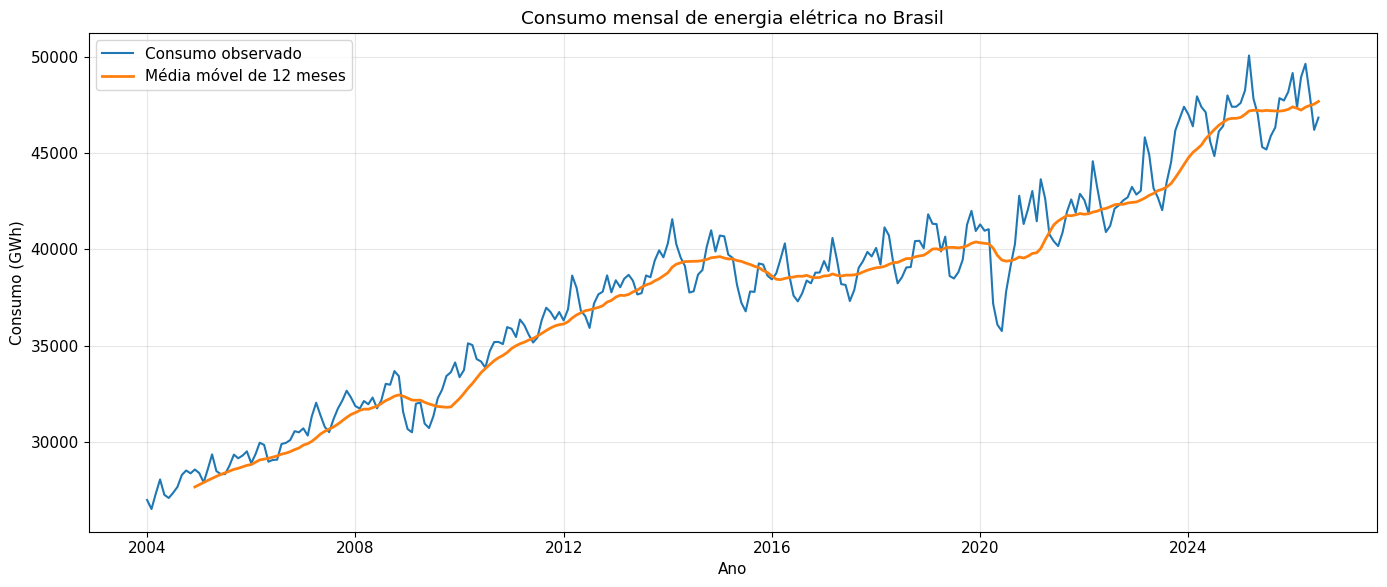

In [ ]:

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    serie.index,
    serie.values,
    label="Consumo observado",
    linewidth=1.5,
)

ax.plot(
    serie.rolling(12).mean(),
    label="Média móvel de 12 meses",
    linewidth=2,
)

ax.set_title(
    "Consumo mensal de energia elétrica no Brasil"
)

ax.set_xlabel("Ano")
ax.set_ylabel("Consumo (GWh)")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Separação da série em treino, validação e teste.

In [ ]:

# Últimos 24 meses: teste
N_TESTE = 24

# 36 meses anteriores: validação
N_VALIDACAO = 36

treino = serie.iloc[:-(N_TESTE + N_VALIDACAO)]

validacao = serie.iloc[
    -(N_TESTE + N_VALIDACAO):-N_TESTE
]

teste = serie.iloc[-N_TESTE:]

print(
    "Treinamento:",
    treino.index.min().date(),
    "até",
    treino.index.max().date(),
)

print(
    "Validação:",
    validacao.index.min().date(),
    "até",
    validacao.index.max().date(),
)

print(
    "Teste:",
    teste.index.min().date(),
    "até",
    teste.index.max().date(),
)

Treinamento: 2004-01-01 até 2021-07-01
Validação: 2021-08-01 até 2024-07-01
Teste: 2024-08-01 até 2026-07-01


Definição dos modelos candidatos. HW-1 com tendência aditiva e sazonalidade aditiva. HW-2 com tendência aditiva e sazonalidade multiplicativa. HW-3 com tedência aditiva amortecida e sazonalidade aditiva. HW-4 com tendência aditiva amortecida e sazonalidade multiplicativa.

In [ ]:

from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Configurações dos modelos candidatos
CONFIGURACOES = {
    "HW-1": {
        "trend": "add",
        "seasonal": "add",
        "damped_trend": False,
    },
    "HW-2": {
        "trend": "add",
        "seasonal": "mul",
        "damped_trend": False,
    },
    "HW-3": {
        "trend": "add",
        "seasonal": "add",
        "damped_trend": True,
    },
    "HW-4": {
        "trend": "add",
        "seasonal": "mul",
        "damped_trend": True,
    },
}


def ajustar_holt_winters(dados, configuracao):
    """
    Ajusta um modelo Holt-Winters à série mensal.

    Parameters
    ----------
    dados : pd.Series
        Série temporal de consumo em GWh.
    configuracao : dict
        Parâmetros da especificação Holt-Winters.

    Returns
    -------
    HoltWintersResults
        Modelo ajustado.
    """
    modelo = ExponentialSmoothing(
        dados,
        trend=configuracao["trend"],
        seasonal=configuracao["seasonal"],
        damped_trend=configuracao["damped_trend"],
        seasonal_periods=12,
        initialization_method="estimated",
    )

    ajuste = modelo.fit(
        optimized=True,
        use_brute=True,
    )

    return ajuste


# Ajuste preliminar dos quatro modelos
modelos_ajustados = {}

for nome, configuracao in CONFIGURACOES.items():

    print(f"Ajustando modelo {nome}...")

    ajuste = ajustar_holt_winters(
        treino,
        configuracao,
    )

    modelos_ajustados[nome] = ajuste

    print(f"AIC: {ajuste.aic:.4f}")
    print(f"BIC: {ajuste.bic:.4f}")
    print("-" * 40)

Ajustando modelo HW-1...
AIC: 2781.5831
BIC: 2835.2128
----------------------------------------
Ajustando modelo HW-2...
AIC: 2767.9394
BIC: 2821.5691
----------------------------------------
Ajustando modelo HW-3...
AIC: 2781.3089
BIC: 2838.2905
----------------------------------------
Ajustando modelo HW-4...
AIC: 2769.2273
BIC: 2826.2089
----------------------------------------


Função para calcular as métricas.

In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


def calcular_metricas(y_real, y_previsto):
    """
    Calcula métricas de avaliação das previsões.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_previsto = np.asarray(y_previsto, dtype=float)

    mae = mean_absolute_error(y_real, y_previsto)
    mse = mean_squared_error(y_real, y_previsto)
    rmse = np.sqrt(mse)

    # MAPE em percentual
    mape = np.mean(
        np.abs((y_real - y_previsto) / y_real)
    ) * 100

    # sMAPE em percentual
    denominador = np.abs(y_real) + np.abs(y_previsto)

    smape = np.mean(
        200 * np.abs(y_real - y_previsto) / denominador
    )

    # Coeficiente de determinação
    if len(y_real) >= 2:
        r2 = r2_score(y_real, y_previsto)
    else:
        r2 = np.nan

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "sMAPE (%)": smape,
        "R²": r2,
    }

Validação temporal e seleção do modelo.

In [ ]:

def avaliar_origens_moveis(
    serie_completa,
    inicio_avaliacao,
    fim_avaliacao,
    configuracao,
    passo=1,
):
    """
    Avalia previsões utilizando janela expansiva.

    Para cada origem, ajusta o modelo somente com os
    dados disponíveis até aquela data.
    """
    resultados = []

    inicio_pos = serie_completa.index.get_loc(
        inicio_avaliacao
    )

    fim_pos = serie_completa.index.get_loc(
        fim_avaliacao
    )

    for origem in range(inicio_pos, fim_pos + 1, passo):

        dados_treino = serie_completa.iloc[:origem]

        ajuste = ajustar_holt_winters(
            dados_treino,
            configuracao,
        )

        previsao = ajuste.forecast(max(HORIZONTES))

        for h in HORIZONTES:

            pos_alvo = origem + h - 1

            if pos_alvo > fim_pos:
                continue

            valor_real = serie_completa.iloc[pos_alvo]
            valor_previsto = previsao.iloc[h - 1]

            resultados.append({
                "Origem": dados_treino.index[-1],
                "Data_alvo": serie_completa.index[pos_alvo],
                "Horizonte": h,
                "Real": valor_real,
                "Previsto": valor_previsto,
            })

    return pd.DataFrame(resultados)


# Série disponível até o final da validação
serie_validacao = pd.concat([treino, validacao])

resultados_validacao = {}
comparacao_modelos = []

for nome, configuracao in CONFIGURACOES.items():

    print(f"Avaliando modelo {nome}...")

    previsoes = avaliar_origens_moveis(
        serie_completa=serie_validacao,
        inicio_avaliacao=validacao.index.min(),
        fim_avaliacao=validacao.index.max(),
        configuracao=configuracao,
        passo=3,
    )

    resultados_validacao[nome] = previsoes

    erros = []

    for h in HORIZONTES:

        dados_h = previsoes[
            previsoes["Horizonte"] == h
        ]

        metricas = calcular_metricas(
            dados_h["Real"],
            dados_h["Previsto"],
        )

        erros.append(metricas["MAE"])

    comparacao_modelos.append({
        "Modelo": nome,
        "MAE médio": np.mean(erros),
    })


tabela_comparacao = pd.DataFrame(
    comparacao_modelos
).sort_values("MAE médio")

display(tabela_comparacao)

melhor_nome = tabela_comparacao.iloc[0]["Modelo"]
melhor_configuracao = CONFIGURACOES[melhor_nome]

print("\nModelo selecionado:", melhor_nome)
print("Configuração:", melhor_configuracao)

Avaliando modelo HW-1...
Avaliando modelo HW-2...


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


Avaliando modelo HW-3...
Avaliando modelo HW-4...


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


,Modelo,MAE médio
1,HW-2,824.201648
3,HW-4,956.364618
0,HW-1,1172.987115
2,HW-3,1218.208308



Modelo selecionado: HW-2
Configuração: {'trend': 'add', 'seasonal': 'mul', 'damped_trend': False}


Avaliação fora da amostra.

In [ ]:

resultado_teste = avaliar_origens_moveis(
    serie_completa=serie,
    inicio_avaliacao=teste.index.min(),
    fim_avaliacao=teste.index.max(),
    configuracao=melhor_configuracao,
    passo=1,
)

display(resultado_teste.head())

# Calcula as métricas para cada horizonte
tabela_metricas = []

for h in HORIZONTES:

    dados_h = resultado_teste[
        resultado_teste["Horizonte"] == h
    ].copy()

    metricas = calcular_metricas(
        dados_h["Real"],
        dados_h["Previsto"],
    )

    tabela_metricas.append({
        "Horizonte": h,
        "Nº previsões": len(dados_h),
        **metricas,
    })


tabela_metricas = pd.DataFrame(tabela_metricas)

print("\nMétricas de desempenho por horizonte:")

display(tabela_metricas.round(4))

,Origem,Data_alvo,Horizonte,Real,Previsto
0,2024-07-01,2024-08-01,1,46122.399943,45866.825095
1,2024-07-01,2024-10-01,3,47994.158482,47419.742588
2,2024-07-01,2025-01-01,6,47597.235964,47651.354019
3,2024-07-01,2025-07-01,12,45184.502081,45939.148141
4,2024-08-01,2024-09-01,1,46408.096769,46754.333700



Métricas de desempenho por horizonte:


,Horizonte,Nº previsões,MAE,MSE,RMSE,MAPE (%),sMAPE (%),R²
0,1,24,593.6625,5.528155e+05,743.5156,1.2458,1.2439,0.6444
1,3,22,658.9233,6.965693e+05,834.6073,1.3914,1.3885,0.5522
2,6,19,828.5975,1.113803e+06,1055.3685,1.7446,1.7346,0.3772
3,12,13,917.3223,1.268352e+06,1126.2113,1.9347,1.9091,0.2416


Gráfico das previsões e dos erros.

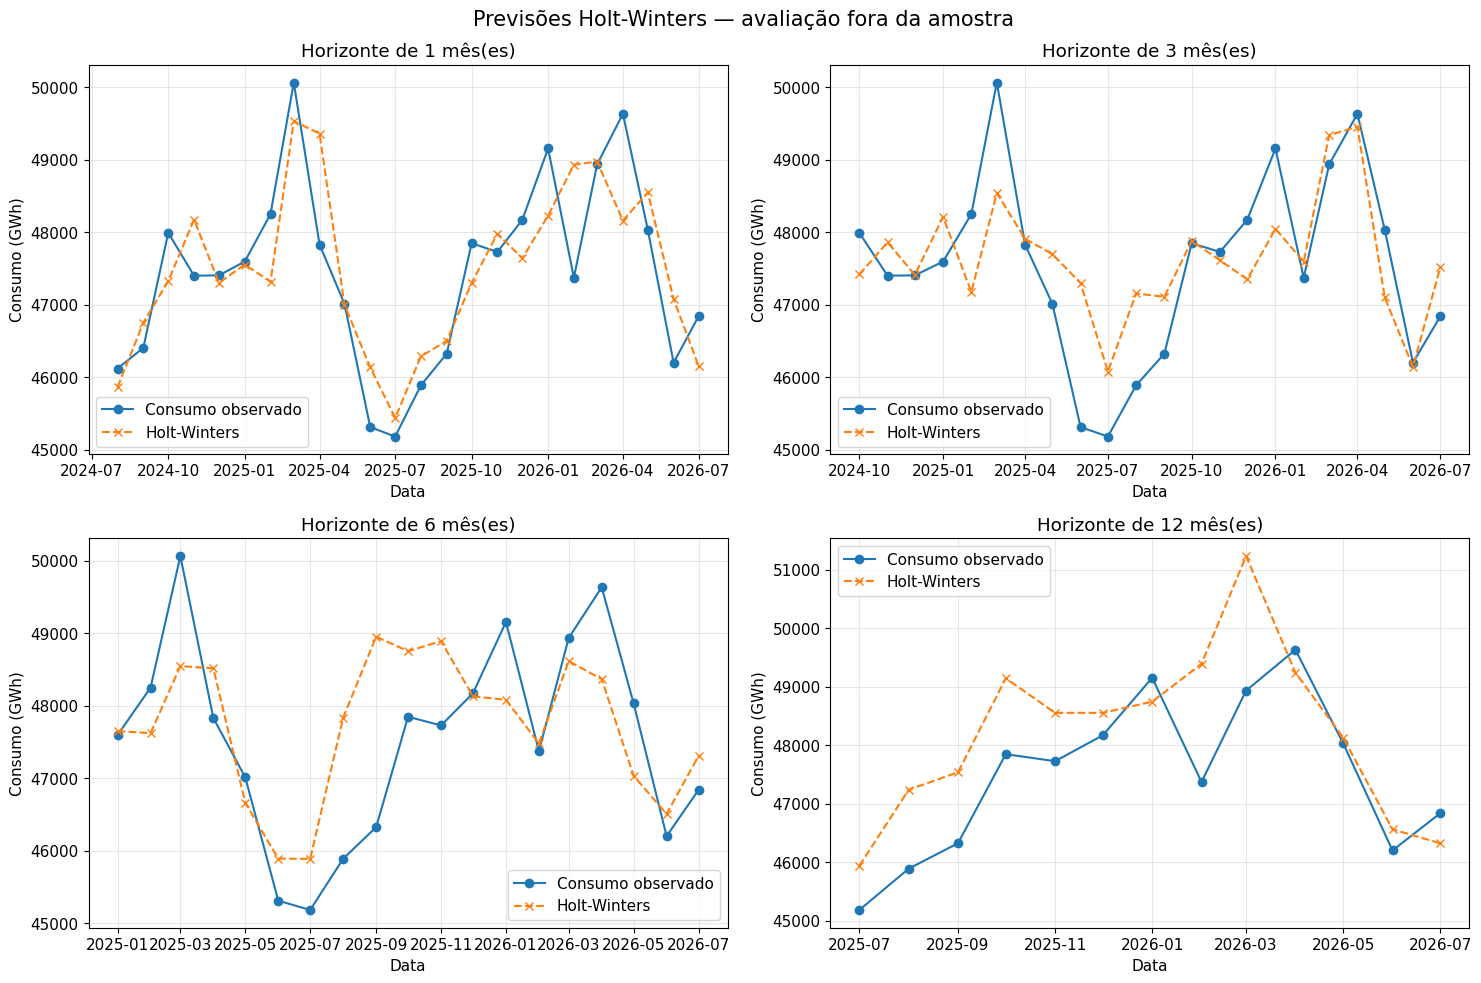

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10),
)

for ax, h in zip(axes.flatten(), HORIZONTES):

    dados_h = resultado_teste[
        resultado_teste["Horizonte"] == h
    ].copy()

    ax.plot(
        dados_h["Data_alvo"],
        dados_h["Real"],
        label="Consumo observado",
        marker="o",
        linewidth=1.5,
    )

    ax.plot(
        dados_h["Data_alvo"],
        dados_h["Previsto"],
        label="Holt-Winters",
        marker="x",
        linestyle="--",
    )

    ax.set_title(f"Horizonte de {h} mês(es)")

    ax.set_xlabel("Data")
    ax.set_ylabel("Consumo (GWh)")

    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Previsões Holt-Winters — avaliação fora da amostra",
    fontsize=15,
)

plt.tight_layout()
plt.show()

Erro da previsão futura.

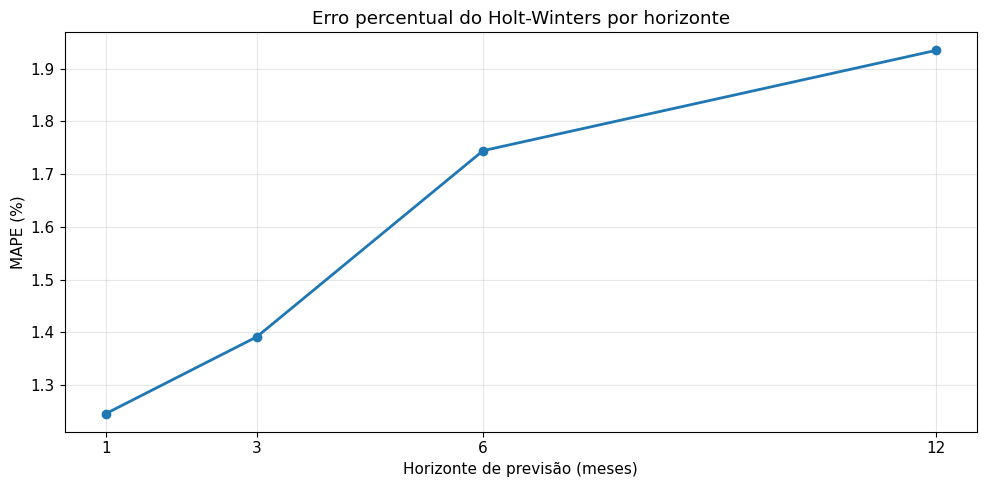

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    tabela_metricas["Horizonte"],
    tabela_metricas["MAPE (%)"],
    marker="o",
    linewidth=2,
)

plt.xlabel("Horizonte de previsão (meses)")
plt.ylabel("MAPE (%)")

plt.title(
    "Erro percentual do Holt-Winters por horizonte"
)

plt.xticks(HORIZONTES)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Previsão futura.

In [ ]:

# Ajuste com toda a série histórica
modelo_final = ajustar_holt_winters(
    serie,
    melhor_configuracao,
)

# Previsão dos próximos 12 meses
previsao_futura = modelo_final.forecast(12)

# Organização dos resultados
tabela_previsoes = pd.DataFrame({
    "Data": previsao_futura.index,
    "Consumo_previsto_GWh": previsao_futura.values,
})

# Conversão para MWh
tabela_previsoes["Consumo_previsto_MWh"] = (
    tabela_previsoes["Consumo_previsto_GWh"] * 1000
)

tabela_previsoes["Horizonte"] = np.arange(1, 13)

print("Previsão do consumo de energia elétrica:")
display(tabela_previsoes.round(2))

Previsão do consumo de energia elétrica:


,Data,Consumo_previsto_GWh,Consumo_previsto_MWh,Horizonte
0,2026-08-01,47903.20,47903199.96,1
1,2026-09-01,48520.45,48520454.42,2
2,2026-10-01,49570.22,49570219.24,3
3,2026-11-01,49682.13,49682127.96,4
4,2026-12-01,49620.30,49620297.88,5
5,2027-01-01,49835.72,49835717.28,6
6,2027-02-01,49499.22,49499215.52,7
7,2027-03-01,50875.73,50875734.65,8
8,2027-04-01,50155.20,50155198.97,9
9,2027-05-01,48977.26,48977260.15,10


Previsão nos horizontes selecionados.

In [ ]:

previsoes_horizontes = tabela_previsoes[
    tabela_previsoes["Horizonte"].isin(HORIZONTES)
].copy()

print("Previsões para os horizontes selecionados:")

display(previsoes_horizontes.round(2))

Previsões para os horizontes selecionados:


,Data,Consumo_previsto_GWh,Consumo_previsto_MWh,Horizonte
0,2026-08-01,47903.20,47903199.96,1
2,2026-10-01,49570.22,49570219.24,3
5,2027-01-01,49835.72,49835717.28,6
11,2027-07-01,47935.59,47935593.40,12


Gráfico de previsão futura.

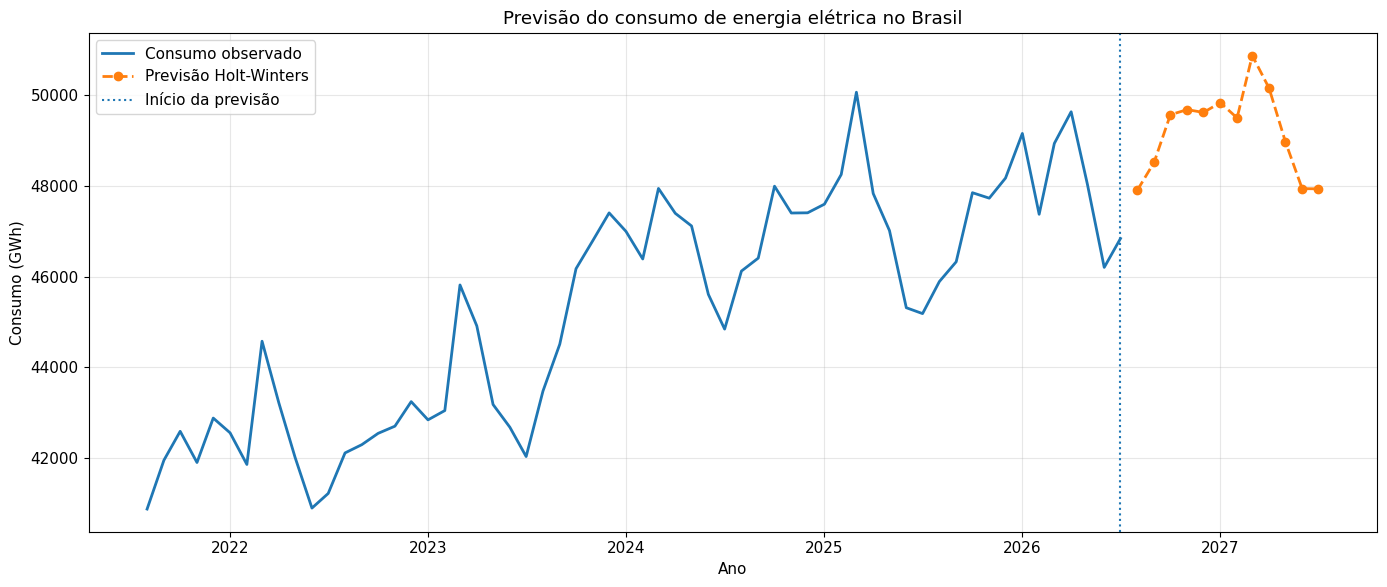

In [ ]:

plt.figure(figsize=(14, 6))

# Últimos 60 meses da série histórica
historico_recente = serie.iloc[-60:]

plt.plot(
    historico_recente.index,
    historico_recente.values,
    label="Consumo observado",
    linewidth=2,
)

plt.plot(
    previsao_futura.index,
    previsao_futura.values,
    label="Previsão Holt-Winters",
    linestyle="--",
    marker="o",
    linewidth=2,
)

plt.axvline(
    serie.index.max(),
    linestyle=":",
    label="Início da previsão",
)

plt.title(
    "Previsão do consumo de energia elétrica no Brasil"
)

plt.xlabel("Ano")
plt.ylabel("Consumo (GWh)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Exportação dos resultados para Excel.

In [ ]:

from google.colab import files

arquivo_saida = "Resultados_Holt_Winters_Energia.xlsx"

with pd.ExcelWriter(
    arquivo_saida,
    engine="openpyxl",
) as writer:

    tabela_comparacao.to_excel(
        writer,
        sheet_name="Selecao_Modelo",
        index=False,
    )

    tabela_metricas.to_excel(
        writer,
        sheet_name="Metricas_Teste",
        index=False,
    )

    resultado_teste.to_excel(
        writer,
        sheet_name="Previsoes_Teste",
        index=False,
    )

    tabela_previsoes.to_excel(
        writer,
        sheet_name="Previsao_12_Meses",
        index=False,
    )

    previsoes_horizontes.to_excel(
        writer,
        sheet_name="Horizontes_Selecionados",
        index=False,
    )

print("Arquivo gerado:", arquivo_saida)

files.download(arquivo_saida)

Arquivo gerado: Resultados_Holt_Winters_Energia.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>